# RoboCasa365［机器人厨房仿真基准］：AMD［超威半导体］设备真实训练与评估

本流程使用官方三相机、16 维状态、12 维动作数据，真实更新通用机器人策略模型的视觉语言投影层，再将新权重放回官方厨房仿真。冻结其余参数，并保存基座身份、训练增量、优化器和随机状态。它是低存储适配训练，不是从零训练整模型，也不宣称复现历史 230/800。

流程：固定源码与依赖 → 后端预检 → 数据审计与统计 → 真实训练 → 本次权重身份核对 → 官方闭环评估 → 视频和逐回合结果。历史比赛成绩不参与本次结果计算。

## 阅读与完整复现

本笔记本保存真实设备结果，下载后不运行也能查看训练曲线、同种子逐回合对照和代表性视频。默认模式只读取随课程分发的证据快照，不需要设备。

完整复现时设置环境变量 `AMD_RUN_FULL=1`，修改下方路径和新的运行目录，再从头执行全部单元。正式步数、全数据范围及 20 个种子已经写入配置。下载和安装单独显式启用；已准备好的设备不重复下载。

证据快照是此前实际任务的只读记录。下方完整复现代码的关闭状态不会被称作本次重新训练通过；历史整本执行验收另行标注。

In [1]:
from pathlib import Path
import json
import os
import sys

TOPIC = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code/amd_benchmarks').is_dir()), None)
if TOPIC is None:
    raise FileNotFoundError('Start Jupyter from the AMD topic directory or notebooks/.')
sys.path.insert(0, str(TOPIC / 'code'))
from amd_benchmarks.notebook_api import run_stage, download_assets, inspect_run, plot_metrics, show_videos
WORK_ROOT = Path(os.environ.get('AMD_WORK_ROOT', str(Path.home() / 'amd-course')))
SRC_ROOT = Path(os.environ.get('SRC_ROOT', str(WORK_ROOT / 'src')))
DATA_ROOT = Path(os.environ.get('DATA_ROOT', str(WORK_ROOT / 'datasets')))
MODEL_ROOT = Path(os.environ.get('MODEL_ROOT', str(WORK_ROOT / 'models')))
ENV_ROOT = Path(os.environ.get('ENV_ROOT', str(WORK_ROOT / 'envs')))
RUN_ROOT = Path(os.environ.get('RUN_ROOT', str(WORK_ROOT / 'runs')))

from amd_benchmarks.evidence import training_summary, plot_training, compare_policies, show_recorded_videos, show_execution_validation, record_live_run
RUN_FULL = os.environ.get('AMD_RUN_FULL', '0') == '1'
RECORDED = TOPIC / 'notebooks/results' / 'robocasa'
print('完整训练和评估启用：', RUN_FULL)


完整训练和评估启用： False


## 已记录的正式结果

结果读取随笔记本附带的原始指标、权重身份、配置和逐回合文件，并校验内容指纹。记录中的数据范围是训练采样来源，不等于每个样本都被训练遍历。

记录项,实测或配置
任务,PickPlaceCounterToCabinet
数据回合／帧数,502 / 131904
真实已记录更新／目标,3000 / 3000
实际批量／梯度累积／有效批量,1 / 1 / 1
学习率或峰值学习率,1e-05
可训练参数,201437184
最后记录损失,0.034190669655799866
正式训练状态,完成
原始证据目录,/home/aup/amd-notebook-work/runs/robocasa-formal-20261023-v1
实测训练阶段耗时／小时,0.424


样本更新次数／数据帧数： 0.0227
该比值用于理解数据使用规模；随机有放回采样不保证每个样本都已遍历。
本次权重内容指纹： 9d64f32346807e6071261b150434cbcaa0765c3a4a0569617e5bf51f9ce000fe
参数更新前后指纹是否不同： True


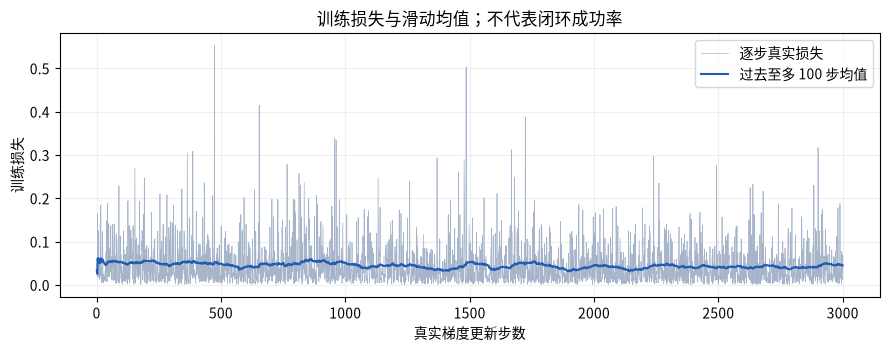

In [2]:
recorded_summary = training_summary(RECORDED)
plot_training(RECORDED)


In [3]:
compare_policies(RECORDED)


策略,成功回合／完整分母,成功率,权重指纹前缀
原始基座,14 / 20,70.0%,181b64f0bf07e46b
本次训练后权重,14 / 20,70.0%,9d64f32346807e60


种子,基座,训练后,同种子变化
100,成功,成功,相同
101,成功,失败,退步
102,失败,失败,相同
103,成功,成功,相同
104,成功,成功,相同
105,失败,成功,改善
106,失败,失败,相同
107,成功,成功,相同
108,成功,成功,相同
109,失败,失败,相同


总体成功率差： +0.0 个百分点
本结果只适用于记录的单任务、种子、划分及配方；相同成功率不代表每个回合行为相同。


In [4]:
show_recorded_videos(RECORDED)


**原始基座 · 种子 101 · 成功**

**原始基座 · 种子 105 · 失败**

**本次训练后权重 · 种子 101 · 失败**

**本次训练后权重 · 种子 105 · 成功**

## 完整运行：固定源码、数据、训练、对照与评估

以下单元按依赖顺序执行完整任务。训练和评估会等待真实进程完成，失败保留日志并使单元报错。正式训练不能用少量步骤的结果代替。

## 1. 路径与运行配置

把源码、数据、模型与运行目录放在持久化磁盘。复用已有解释器，不把数组计算与模拟器的依赖混装。当前默认训练和评估开关关闭；后续单元启用后会执行真实负载。

In [5]:
CONFIG = {
    'benchmark': 'robocasa',
    'task': 'PickPlaceCounterToCabinet',
    'source_root': str(SRC_ROOT / "Isaac-GR00T"),
    'robocasa_root': str(SRC_ROOT / "robocasa"),
    'robosuite_root': str(SRC_ROOT / "robosuite"),
    'dataset_root': str(DATA_ROOT / "robocasa365/PickPlaceCounterToCabinet"),
    'base_model': str(MODEL_ROOT / "robocasa365/gr00t_n1-5_multitask_120000"),
    'run_root': str(RUN_ROOT / "robocasa-projector-v1"),
    'training_recipe': 'gr00t_vl_projector_only',
    'training_episodes': 502,
    'minimum_free_gib': 8,
    'eval_episodes': 20,
    'eval_seeds': list(range(100, 120)),
    'eval_split': 'target',
    'port': 8121,
    'batch_size': 1,
    'learning_rate': 1e-05,
    'seed': 42,
    'steps': 3000,
    'save_every': 1000,
    'resume': False,
}
# An explicit profile can point at existing source, data and environments.
PROFILE = os.environ.get('AMD_ROBOCASA_CONFIG')
if PROFILE:
    CONFIG = json.loads(Path(PROFILE).read_text(encoding='utf-8'))
TRAIN_PYTHON = Path(os.environ.get('TRAIN_PYTHON', str(ENV_ROOT / 'robocasa365-rocm-py312/bin/python')))
print(json.dumps(CONFIG, ensure_ascii=False, indent=2))
print('Interpreter:', TRAIN_PYTHON)

# This example profile points at the verified AMD device. Edit all paths on another machine.
USE_VERIFIED_DEVICE_PROFILE = os.environ.get('AMD_USE_DEVICE_PROFILE', '0') == '1'
if USE_VERIFIED_DEVICE_PROFILE and not PROFILE:
    CONFIG = json.loads((TOPIC / 'reproducibility/robocasa-device-profile.json').read_text(encoding='utf-8'))
CONFIG['run_root'] = os.environ.get('AMD_NEW_RUN_ROOT', CONFIG['run_root'])
print('实际运行配置：', json.dumps(CONFIG, ensure_ascii=False, indent=2))


{
  "benchmark": "robocasa",
  "task": "PickPlaceCounterToCabinet",
  "source_root": "/home/ubuntu/amd-course/src/Isaac-GR00T",
  "robocasa_root": "/home/ubuntu/amd-course/src/robocasa",
  "robosuite_root": "/home/ubuntu/amd-course/src/robosuite",
  "dataset_root": "/home/ubuntu/amd-course/datasets/robocasa365/PickPlaceCounterToCabinet",
  "base_model": "/home/ubuntu/amd-course/models/robocasa365/gr00t_n1-5_multitask_120000",
  "run_root": "/home/ubuntu/amd-course/runs/robocasa-projector-v1",
  "training_recipe": "gr00t_vl_projector_only",
  "training_episodes": 502,
  "minimum_free_gib": 8,
  "eval_episodes": 20,
  "eval_seeds": [
    100,
    101,
    102,
    103,
    104,
    105,
    106,
    107,
    108,
    109,
    110,
    111,
    112,
    113,
    114,
    115,
    116,
    117,
    118,
    119
  ],
  "eval_split": "target",
  "port": 8121,
  "batch_size": 1,
  "learning_rate": 1e-05,
  "seed": 42,
  "steps": 3000,
  "save_every": 1000,
  "resume": false
}
Interpreter: /ho

### 环境、版本与资源准备



厨房路径需要官方 `robocasa`、`robosuite` 和 RoboCasa365 配套的 `Isaac-GR00T`。训练器读取 `panda_omron` 数据配置，使用官方机器人元数据切分 16 维状态和 12 维动作。训练数据必须是相应任务的真实三相机数据。

灵巧手路径需要包含 `openpi/`、`configs/rand_obj/` 和模拟器客户端的 DexJoCo 工程。低秩适配配置来自该工程的 `openpi.training.config`，不得用其他机器人配置替代。`lerobot_source` 可以显式指向支持第三版数据格式的机器人学习框架源码；已有环境中的旧版框架不能读取此数据格式。

依赖安装复用各项目解释器。先运行预检，禁止用处理器回退通过设备验收。资源下载单元要求 `DOWNLOAD_ENTRY` 指向已配置的下载入口；源码、模型及数据来源分别见第 11、12 章。大文件放在持久化磁盘，不放在课程仓库。

## 固定版本与设备配置

`reproducibility/source-manifest.json` 记录源码提交及关键文件内容指纹；两个环境清单记录实机安装版本。这些清单用于比对，不是可直接整表安装的依赖锁；厨房环境含系统继承包，设备专用轮包也需要对应官方索引。新建环境须先按第 10–12 章安装设备计算栈，再按清单核对核心库，禁止直接安装上游默认的另一设备计算依赖。

| 组件 | 固定版本 |
| --- | --- |
| 厨房策略源码 | `9d7d7a9eb7ad30bd8ce30448d9ab53a918b45b10` |
| 厨房仿真源码 | `b4684e6ee37d377cc392e98302a6b916d588b415` |
| 机器人仿真组件 | `5ce6643f3092639d08f7b0f90ed1c6a84f50552c` |
| 灵巧手兼容分支源码 | `46fcd70db460b3be5487387adab2aaf3e2e7b74f` |
| 第三版数据读取源码 | `00b5f65752e1e5882f96c99a34e1d8b6d5d67f11` |

灵巧手参考提交包含新版检查点兼容修改，来自公开兼容分支，不能仅克隆官方主线后假设源码相同：

```bash
git clone https://github.com/Ethan-Chen-plus/dexjoco.git "$SRC_ROOT/dexjoco"
git -C "$SRC_ROOT/dexjoco" checkout 46fcd70db460b3be5487387adab2aaf3e2e7b74f
```

厨房核心版本为设备张量库 `2.12.1+rocm7.2`、视觉库 `0.27.1+rocm7.2`、模型库 `4.51.3`、扩散库 `0.30.2`。灵巧手采用数组库 `0.10.0`、设备插件 `0.10.0+rocm7.14.0`、神经网络库 `0.12.8`、检查点库 `0.12.1`，配套处理器版张量库 `2.9.0+cpu` 和视觉库 `0.24.0+cpu`。

灵巧手已有数组计算环境补齐数据加载依赖时，可通过专用下载入口安装：

```bash
"$DOWNLOAD_ENTRY" "$TRAIN_PYTHON" -m pip install \
  'torch==2.9.0+cpu' 'torchvision==0.24.0+cpu' \
  --index-url https://download.pytorch.org/whl/cpu
"$DOWNLOAD_ENTRY" "$TRAIN_PYTHON" -m pip install \
  'datasets==4.0.0' 'pandas==2.3.3' 'pyarrow==21.0.0' \
  'av==15.1.0' 'fsspec==2025.3.0' 'dill==0.3.8' \
  'multiprocess==0.70.16' 'accelerate==1.10.1' \
  'wandb==0.19.11' 'protobuf==6.33.6'
```

课程辅助模块在子进程内适配神经网络库的参数遍历、数组库的自动分片模式，并关闭不适配该设备共享内存上限的编译优先融合阶段；不覆盖上游源码。厨房辅助模块使用数学注意力内核，并在模型库内适配注意力映射。更换核心版本须重新检查反向梯度是否有限。

两个 `*-device-profile.json` 配置指向已有设备路径，采用新的正式实验目录；它们是待运行配置，不代表已完成正式训练。启动厨房笔记本时设置：

```bash
export AMD_ROBOCASA_CONFIG="$PWD/reproducibility/robocasa-device-profile.json"
export TRAIN_PYTHON=/home/aup/envs/robocasa365-rocm-py312/bin/python
```

灵巧手改用 `AMD_DEXJOCO_CONFIG` 和对应解释器。启动目录应为本专题根目录；两本笔记本也支持从其 `notebooks/` 目录打开。交互内核与设备训练进程分开。`TRAIN_PYTHON` 选择训练解释器，交互内核可以复用厨房环境。给已有交互解释器安装固定组件：

```bash
"$DOWNLOAD_ENTRY" "$NOTEBOOK_PYTHON" -m pip install \
  'ipykernel==6.29.5' 'ipython==8.37.0' \
  'nbclient==0.10.2' 'nbformat==5.10.4' \
  'matplotlib==3.10.3' 'contourpy==1.3.2' 'kiwisolver==1.4.9'
```

旧系统图表轮包可能按旧数组库编译；不能仅检查模块是否存在，必须实际生成图表。

灵巧手还需预取语言分词资源。笔记本下载单元包含对应的公开云存储命令；`asset_cache` 指定其持久缓存目录，已有设备配置复用现存缓存。模型与数据阶段拒绝临时发起资源下载，缺缓存会明确报错。

灵巧手训练默认要求至少 24 GiB 可用系统内存。这是启动门槛，不是实测峰值或不会耗尽内存的保证；统一内存同时承载主机加载、设备参数、编译与优化器。按运行时峰值调整门槛，并保留系统余量。磁盘空闲检查同样只检查启动门槛。灵巧手正式实验默认要求 24 GiB 空闲磁盘，为原生检查点和原子保存时的新旧副本留空间；一份短程原生检查点约为 8.7 GiB。

可以使用配套的整本执行器验证单元顺序：

```bash
export TRAIN_PYTHON=/home/aup/envs/openpi-amd-jax010/bin/python
export JUPYTER_PATH=/home/aup/amd-notebook-work/jupyter/share/jupyter
/home/aup/envs/robocasa365-rocm-py312/bin/python code/execute_course_notebook.py \
  notebooks/18_dexjoco_amd_train_eval.ipynb \
  --profile reproducibility/dexjoco-device-profile.json \
  --kernel amd-course --enable-workloads --output /path/to/new/executed_18.ipynb
```

使用前把配置中的运行目录改为新目录，需要检查环境时，可在独立目录将目标总步数改为 2–20、评估选 1 个种子；该结果只用于执行验收。正式配置使用全部数据与完整步数，不能将短程结果作为正式实验。其他机器用自己的交互解释器及内核名称；输出路径必须是新文件。执行器默认不限制单元时长，支持长训练；可用 `--timeout` 显式设置秒数。执行失败仍保存当时输出并返回异常。此执行器不会自动启用资源下载。



## 2. 源码、依赖与资产

按配套说明中的固定版本准备源码及环境。下载单元真实执行资源下载命令；已有完整资产时保持关闭。`DOWNLOAD_ENTRY` 指向已配置的专用下载入口。模型权限需事先授权；不把访问令牌写进笔记本。

In [6]:
DOWNLOADS = [
    ['hf', 'download', 'jellyho/robocasa365-PickPlaceCounterToCabinet', '--repo-type', 'dataset', '--local-dir', CONFIG['dataset_root']],
    ['hf', 'download', 'robocasa/robocasa365_checkpoints', '--include', 'gr00t_n1-5_multitask_120000/**', '--local-dir', str(Path(CONFIG['base_model']).parent)],
]
RUN_DOWNLOAD = False
download_assets(CONFIG, DOWNLOADS, enabled=RUN_DOWNLOAD)


Resource downloads disabled; reuse existing local assets or enable this stage explicitly.


## 3. AMD［超威半导体］后端预检

设备检查会做真实矩阵乘法，并拒绝处理器回退。检查通过只代表运行后端可用，不代表机器人任务成功。

In [7]:
RUN_PREFLIGHT = RUN_FULL
preflight_result = run_stage(CONFIG, 'preflight', TRAIN_PYTHON, enabled=RUN_PREFLIGHT)


preflight: disabled. No workload was executed and no result is claimed.


## 4. 数据准备与输入契约

将数据整理为逐回合读取格式，通过视频软链接避免重复复制大文件。保留原始视频的绝对时间戳，并验证三相机时间原点一致；状态和动作切片读取官方机器人元数据。训练统计只从选中的训练回合计算。

In [8]:
RUN_PREPARE = RUN_FULL
prepare_result = run_stage(CONFIG, 'prepare', TRAIN_PYTHON, enabled=RUN_PREPARE)


prepare: disabled. No workload was executed and no result is claimed.


## 5. 启动前确认训练计划

下表显示实际批量、梯度累积和步数。学习率与冻结范围写入运行记录；可训练参数量及显存峰值以运行时实测为准。本节正式运行使用配置中的完整目标步数；少量步数验收必须使用其他独立目录，不能混入正式对照。

In [9]:
plan = {k: CONFIG[k] for k in ['task', 'steps', 'batch_size', 'learning_rate', 'training_recipe']}
plan.update(gradient_accumulation=1, effective_batch=CONFIG['batch_size'], memory_basis=('RoboCasa: batch 1 device allocation peak 10.73 GiB measured in a 3-step validation; host RAM is additional.' if CONFIG['benchmark'] == 'robocasa' else 'DexJoCo: 32-48 GiB unified working-memory estimate from 7.2 GiB weights, host/device copies and compilation/activations; full-training peak unverified.'), freeze_scope=('action_head.vlln + action_head.vl_self_attention only' if CONFIG['benchmark'] == 'robocasa' else 'upstream model freeze filter; LoRA and all other parameters outside that filter are trainable'))
print(json.dumps(plan, ensure_ascii=False, indent=2))


{
  "task": "PickPlaceCounterToCabinet",
  "steps": 3000,
  "batch_size": 1,
  "learning_rate": 1e-05,
  "training_recipe": "gr00t_vl_projector_only",
  "gradient_accumulation": 1,
  "effective_batch": 1,
  "memory_basis": "RoboCasa: batch 1 device allocation peak 10.73 GiB measured in a 3-step validation; host RAM is additional.",
  "freeze_scope": "action_head.vlln + action_head.vl_self_attention only"
}


## 6. 执行真实训练

启用后等待真实训练进程结束。异常会保留日志并使单元失败，不读取历史权重补齐结果。已有检查点时必须显式恢复或更换目录。

## 直接展开训练实现

本节把正式运行使用的数据准备、训练和评估实现展开为代码单元。训练入口直接调用下方函数，能够逐步查看冻结范围、损失、梯度、参数更新、保存与加载；配置、训练曲线和历史评估输出沿用本篇对应的真实记录。

### 正式配方与训练、保存和评估

下面是实际源码展开后的代码单元，包含数据、模型、损失、梯度更新和保存逻辑；完整运行开关打开时在当前笔记本内执行。来源：`code/amd_benchmarks/robocasa.py`；SHA256［256位安全散列］：`29a2e1b36d1fdf33ca405407509c053ce9cd79b8b9d2873cbdae3ce99624c1f4`。

In [10]:
if RUN_FULL:
    """RoboCasa365 GR00T projector adaptation with composite checkpoints.

    Frozen base weights are referenced by hash. Only trained tensors and optimizer
    state are saved, avoiding a duplicate multi-gigabyte frozen backbone per save.
    """

    import json

    import os

    from pathlib import Path

    import random

    import socket

    import subprocess

    import sys

    import time

    from amd_benchmarks.common import bind_run, disk_gate, fingerprint, reconcile_metrics, require_files, require_free_port, sha256, torch_preflight, write_json

    def setup(c):
        source = Path(c['source_root'])
        for path in [source, Path(c['robocasa_root']), Path(c['robosuite_root'])]:
            sys.path.insert(0, str(path))
        # Numba's optional coverage integration is incompatible with some images.
        # Disable that optional integration in this worker only.
        sys.modules['coverage'] = None
        # HIP allocation before torchvision/timm avoids the known gfx1151 import issue.
        import torch
        if torch.cuda.is_available():
            torch.empty(1, device='cuda')
        torch.backends.cuda.enable_flash_sdp(False)
        torch.backends.cuda.enable_mem_efficient_sdp(False)
        torch.backends.cuda.enable_math_sdp(True)
        os.environ.setdefault('NO_ALBUMENTATIONS_UPDATE', '1')
        from transformers.modeling_utils import ALL_ATTENTION_FUNCTIONS
        from transformers.models.siglip.modeling_siglip import eager_attention_forward
        ALL_ATTENTION_FUNCTIONS['flash_attention_2'] = eager_attention_forward

    def validate_eval_split(c):
        if c.get("eval_split", "pretrain") not in {"pretrain", "target", "all", None}:
            raise ValueError("This pinned RoboCasa version supports pretrain, target, all or None; not test.")

    def preflight(c):
        validate_eval_split(c)
        require_files(c['source_root'], ['gr00t/model/policy.py', 'gr00t/data/dataset.py'])
        require_files(c['dataset_root'], ['meta/info.json', 'meta/tasks.parquet'])
        require_files(c['base_model'], ['config.json', 'model.safetensors.index.json', 'experiment_cfg/metadata.json'])
        setup(c)
        result = torch_preflight()
        result['free_disk_gib'] = disk_gate(c['run_root'], c.get('minimum_free_gib', 3))
        info = json.loads((Path(c['dataset_root']) / 'meta/info.json').read_text())
        assert info['features']['observation.state']['shape'] == [16]
        assert info['features']['action']['shape'] == [12]
        result['dataset_episodes'] = info['total_episodes']
        result['note'] = 'Device and data contract only; not a learned-policy success.'
        return result

    def prepare(c):
        """Create episode-based GR00T views of v3 data without copying videos.

        Preserve absolute video timestamps. Fail if cameras have different time
        origins instead of silently pairing images from different episodes.
        """
        import numpy as np
        import pandas as pd
        source = Path(c['dataset_root'])
        root = Path(c['run_root'])
        dst = root / 'prepared'
        info = json.loads((source / 'meta/info.json').read_text())
        di = fingerprint(source, ['meta/info.json', 'meta/tasks.parquet', 'meta/episodes/**/*.parquet'])
        bi = fingerprint(c['base_model'], ['config.json', '*.safetensors', 'experiment_cfg/metadata.json'])
        bind_run(c, di, bi)
        if (dst / 'prepare_manifest.json').exists():
            prepared = json.loads((dst / 'prepare_manifest.json').read_text())
            expected = min(int(c.get('training_episodes', 32)), info['total_episodes'])
            if prepared['episodes'] != expected:
                raise RuntimeError('Training episode selection changed; use a new run_root.')
            return prepared
        dst.mkdir(parents=True, exist_ok=False)
        (dst / 'meta').mkdir()
        episodes = pd.concat([pd.read_parquet(p) for p in sorted((source / 'meta/episodes').rglob('*.parquet'))])
        episodes = episodes.sort_values('episode_index').head(int(c.get('training_episodes', 32)))
        if len(episodes) < 2:
            raise ValueError('At least two real episodes are required.')
        cameras = [k for k in info['features'] if k.startswith('observation.images.')]
        tables = {}
        metadata = []
        all_state, all_action = [], []
        for _, ep in episodes.iterrows():
            episode = int(ep['episode_index'])
            key = (int(ep['data/chunk_index']), int(ep['data/file_index']))
            if key not in tables:
                tables[key] = pd.read_parquet(source / info['data_path'].format(chunk_index=key[0], file_index=key[1]))
            frame = tables[key][tables[key].episode_index == episode].copy()
            if len(frame) != int(ep['length']):
                raise ValueError(f'Episode {episode}: missing or truncated data.')
            offsets = [float(ep[f'videos/{cam}/from_timestamp']) for cam in cameras]
            if not np.allclose(offsets, offsets[0], atol=1e-4):
                raise ValueError('Camera time origins differ; explicit video segmentation is required.')
            frame['timestamp'] = frame['timestamp'] + offsets[0]
            target = dst / f'data/chunk-{episode // 1000:03d}/episode_{episode:06d}.parquet'
            target.parent.mkdir(parents=True, exist_ok=True)
            frame.to_parquet(target, index=False)
            for cam in cameras:
                video = source / info['video_path'].format(video_key=cam,
                    chunk_index=int(ep[f'videos/{cam}/chunk_index']), file_index=int(ep[f'videos/{cam}/file_index']))
                if not video.is_file():
                    raise FileNotFoundError(video)
                link = dst / f'videos/chunk-{episode // 1000:03d}/{cam}/episode_{episode:06d}.mp4'
                link.parent.mkdir(parents=True, exist_ok=True)
                link.symlink_to(video.resolve())
            metadata.append({'episode_index': episode, 'length': len(frame), 'tasks': list(ep['tasks'])})
            all_state.append(np.stack(frame['observation.state']))
            all_action.append(np.stack(frame['action']))
        modality_path = Path(c['robocasa_root']) / 'robocasa/models/assets/groot_dataset_assets/PandaOmron_modality.json'
        modality = json.loads(modality_path.read_text())
        write_json(dst / 'meta/modality.json', modality)
        # The published v3 task dataset uses the canonical PandaOmron sorted schema.
        assert modality['state']['base_position']['start'] == 0
        assert modality['action']['base_motion']['start'] == 0
        info.update(codebase_version='v2.1', total_episodes=len(metadata),
                    total_frames=sum(x['length'] for x in metadata),
                    data_path='data/chunk-{episode_chunk:03d}/episode_{episode_index:06d}.parquet',
                    video_path='videos/chunk-{episode_chunk:03d}/{video_key}/episode_{episode_index:06d}.mp4')
        write_json(dst / 'meta/info.json', info)
        tasks = pd.read_parquet(source / 'meta/tasks.parquet')
        task_rows = [{'task_index': int(row.task_index), 'task': str(text)} for text, row in tasks.iterrows()]
        (dst / 'meta/tasks.jsonl').write_text(''.join(json.dumps(x) + '\n' for x in task_rows))
        (dst / 'meta/episodes.jsonl').write_text(''.join(json.dumps(x) + '\n' for x in metadata))
        stats = {}
        for name, arrays in [('observation.state', all_state), ('action', all_action)]:
            values = np.concatenate(arrays)
            stats[name] = {k: v.tolist() for k, v in {
                'mean': values.mean(0), 'std': values.std(0), 'min': values.min(0), 'max': values.max(0),
                'q01': np.quantile(values, .01, axis=0), 'q99': np.quantile(values, .99, axis=0)}.items()}
        write_json(dst / 'meta/stats.json', stats)
        result = {'episodes': len(metadata), 'frames': info['total_frames'],
                  'episode_ids': [x['episode_index'] for x in metadata], 'video_mode': 'shared source + absolute timestamps',
                  'modality_sha256': sha256(modality_path), 'dataset_identity': di['sha256'], 'base_identity': bi['sha256']}
        write_json(dst / 'prepare_manifest.json', result)
        return result

    def tensor_digest(state):
        import hashlib
        h = hashlib.sha256()
        for name, tensor in sorted(state.items()):
            h.update(name.encode())
            h.update(tensor.detach().cpu().contiguous().view(__import__('torch').uint8).numpy().tobytes())
        return h.hexdigest()


In [11]:
if RUN_FULL:
    def train(c):
        setup(c)
        import numpy as np
        import torch
        from gr00t.data.dataset import LeRobotSingleDataset
        from gr00t.data.schema import EmbodimentTag
        from gr00t.experiment.data_config import DATA_CONFIG_MAP
        from gr00t.model.gr00t_n1 import GR00T_N1_5
        from gr00t.model.transforms import DefaultDataCollator
        root = Path(c['run_root'])
        require_files(root, ['identity.json', 'prepared/prepare_manifest.json'])
        prepared = json.loads((root / 'prepared/prepare_manifest.json').read_text())
        info = json.loads((Path(c['dataset_root']) / 'meta/info.json').read_text())
        if prepared['episodes'] != min(int(c.get('training_episodes', 32)), info['total_episodes']):
            raise RuntimeError('Training episode selection changed; use a new run_root.')
        disk_gate(root, c.get('minimum_free_gib', 3))
        config = DATA_CONFIG_MAP['panda_omron']
        dataset = LeRobotSingleDataset(dataset_path=root / 'prepared', modality_configs=config.modality_config(),
                                      transforms=config.transform(), embodiment_tag=EmbodimentTag('new_embodiment'),
                                      video_backend='opencv')
        model = GR00T_N1_5.from_pretrained(c['base_model'], tune_llm=False, tune_visual=False,
                                         tune_projector=True, tune_diffusion_model=False).to('cuda')
        # The upstream projector flag also enables large embodiment-specific heads.
        # Restrict this course recipe to the shared VL projector explicitly.
        model.requires_grad_(False)
        model.action_head.vlln.requires_grad_(True)
        model.action_head.vl_self_attention.requires_grad_(True)
        trainable = {name: p for name, p in model.named_parameters() if p.requires_grad}
        if not trainable:
            raise RuntimeError('No trainable projector parameters.')
        optimizer = torch.optim.AdamW(trainable.values(), lr=c['learning_rate'])
        checkpoint = root / 'checkpoint.pt'
        step = 0
        if checkpoint.exists():
            if not c.get('resume', False):
                raise FileExistsError('Checkpoint exists: use resume=True or a fresh run_root.')
            saved = torch.load(checkpoint, map_location='cpu', weights_only=False)
            if saved['identity'] != json.loads((root / 'identity.json').read_text()):
                raise RuntimeError('Checkpoint identity does not match this run.')
            model.load_state_dict(saved['weights'], strict=False)
            optimizer.load_state_dict(saved['optimizer'])
            for state in optimizer.state.values():
                for k, v in state.items():
                    if isinstance(v, torch.Tensor):
                        state[k] = v.to('cuda')
            step = saved['step']
            torch.set_rng_state(saved['torch_rng'])
            torch.cuda.set_rng_state_all(saved['cuda_rng'])
            random.setstate(saved['random_rng'])
            np.random.set_state(saved['numpy_rng'])
            if step >= c['steps']:
                raise ValueError(f'Checkpoint already has {step} steps; set steps above this value to resume.')
        else:
            torch.manual_seed(c['seed']); random.seed(c['seed']); np.random.seed(c['seed'])
        steps_start = step
        recovery = reconcile_metrics(root, step)
        before = tensor_digest(trainable)
        model.train()
        collate = DefaultDataCollator()
        started = time.time()
        final_loss = None
        metrics = root / 'metrics.jsonl'
        print(json.dumps({'trainable_parameters': sum(p.numel() for p in trainable.values()),
                          'batch_size': c['batch_size'], 'gradient_accumulation': 1,
                          'steps_start': step, 'steps_target': c['steps'], 'learning_rate': c['learning_rate']}), flush=True)
        while step < c['steps']:
            # Step-indexed sampling makes sample order reproducible across resume.
            g = torch.Generator().manual_seed(c['seed'] + step)
            indices = torch.randint(len(dataset), (c['batch_size'],), generator=g).tolist()
            batch = collate([dataset[i] for i in indices])
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast('cuda', dtype=torch.bfloat16):
                result = model(batch)
                loss = result['loss']
            if not torch.isfinite(loss):
                raise RuntimeError('Non-finite training loss.')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(trainable.values(), 1.0, error_if_nonfinite=True)
            optimizer.step()
            step += 1
            final_loss = float(loss.detach().cpu())
            record = {'step': step, 'loss': final_loss, 'elapsed_s': time.time() - started,
                      'gpu_peak_bytes': torch.cuda.max_memory_allocated()}
            with metrics.open('a') as f:
                f.write(json.dumps(record) + '\n')
            print(json.dumps(record), flush=True)
            if step % int(c.get('save_every', 100)) == 0 or step == c['steps']:
                full_state = model.state_dict()
                buffer_names = {n for n, _ in model.named_buffers()}
                state = {n: value.detach().cpu() for n, value in full_state.items()
                         if n in trainable or n in buffer_names}
                payload = {'step': step, 'weights': state, 'optimizer': optimizer.state_dict(),
                           'identity': json.loads((root / 'identity.json').read_text()),
                           'torch_rng': torch.get_rng_state(), 'cuda_rng': torch.cuda.get_rng_state_all(),
                           'random_rng': random.getstate(), 'numpy_rng': np.random.get_state()}
                temp = checkpoint.with_suffix('.tmp')
                torch.save(payload, temp)
                temp.replace(checkpoint)
        write_json(root / 'metadata.json', dataset.metadata.model_dump(mode='json'))
        digest = sha256(checkpoint)
        result = {'step': step, 'steps_start': steps_start, 'metrics_recovery': recovery,
                  'loss': final_loss, 'checkpoint': str(checkpoint), 'checkpoint_sha256': digest,
                  'parameter_digest_before': before, 'parameter_digest_after': tensor_digest(trainable),
                  'trainable_parameters': sum(p.numel() for p in trainable.values()),
                  'gpu_peak_bytes': torch.cuda.max_memory_allocated(), 'duration_s': time.time() - started,
                  'recipe': 'GR00T vlln + vl_self_attention only; all other parameters frozen; no gradient accumulation'}
        if step and result['parameter_digest_before'] == result['parameter_digest_after']:
            raise RuntimeError('Training produced no parameter update.')
        write_json(root / 'trained_model.json', result)
        return result

    def policy_record(c):
        root = Path(c['run_root'])
        if c.get('policy_variant') == 'base':
            identity = json.loads((root / 'identity.json').read_text())
            return {'checkpoint_sha256': identity['base_model_identity']['sha256'],
                    'step': 0, 'policy_variant': 'base'}
        return dict(json.loads((root / 'trained_model.json').read_text()), policy_variant='trained')

    def serve(c):
        setup(c)
        import torch
        import numpy as np
        from gr00t.experiment.data_config import DATA_CONFIG_MAP
        from gr00t.model.policy import Gr00tPolicy
        from gr00t.data.schema import DatasetMetadata
        from gr00t.eval.robot import RobotInferenceServer
        torch.manual_seed(c['seed']); np.random.seed(c['seed']); random.seed(c['seed'])
        root = Path(c['run_root'])
        record = policy_record(c)
        config = DATA_CONFIG_MAP['panda_omron']
        policy = Gr00tPolicy(model_path=c['base_model'], modality_config=config.modality_config(),
                             modality_transform=config.transform(), embodiment_tag='new_embodiment', denoising_steps=4)
        if record['policy_variant'] == 'trained':
            if sha256(root / 'checkpoint.pt') != record['checkpoint_sha256']:
                raise RuntimeError('Checkpoint hash changed.')
            saved = torch.load(root / 'checkpoint.pt', map_location='cpu', weights_only=False)
            target_keys = set(policy.model.state_dict())
            weights = dict(saved['weights'])
            for key in set(weights) - target_keys:
                if key.endswith(('.position_ids', '.rotary_emb.inv_freq')):
                    weights.pop(key)
                else:
                    raise RuntimeError(f'Unknown trained tensor: {key}')
            result = policy.model.load_state_dict(weights, strict=False)
            if result.unexpected_keys:
                raise RuntimeError(result.unexpected_keys)
            policy.modality_transform.set_metadata(DatasetMetadata.model_validate(json.loads((root / 'metadata.json').read_text())))
        RobotInferenceServer(policy, port=int(c.get('port', 8121))).run()


In [12]:
if RUN_FULL:
    def evaluate(c):
        validate_eval_split(c)
        require_free_port(c.get('port', 8121))
        setup(c)
        import numpy as np
        from unittest.mock import patch
        from gr00t.eval import simulation
        from gr00t.eval.simulation import SimulationInferenceClient, SimulationConfig, VideoConfig, MultiStepConfig
        from robocasa.utils.dataset_registry_utils import get_task_horizon
        root = Path(c['run_root'])
        require_files(root, ['identity.json'] if c.get('policy_variant') == 'base' else
                      ['trained_model.json', 'checkpoint.pt', 'metadata.json'])
        trained = policy_record(c)
        seeds = c.get('eval_seeds', [None] * int(c.get('eval_episodes', 5)))
        if not seeds or len(seeds) != int(c.get('eval_episodes', len(seeds))):
            raise ValueError('Evaluation episode count must match the seed list.')
        if any(seed is not None for seed in seeds) and len(set(seeds)) != len(seeds):
            raise ValueError('Explicit evaluation seeds must be unique.')
        import uuid
        prefix = 'baseline_' if trained['policy_variant'] == 'base' else 'eval_'
        evaluation = root / (prefix + trained['checkpoint_sha256'][:12] + '_' + uuid.uuid4().hex[:8])
        evaluation.mkdir(exist_ok=False)
        config_path = evaluation / 'evaluation_config.json'
        write_json(config_path, c)
        log = (evaluation / 'server.log').open('w')
        p = subprocess.Popen([sys.executable, '-m', 'amd_benchmarks.robocasa', '--serve', str(config_path)],
                             stdout=log, stderr=subprocess.STDOUT)
        port = int(c.get('port', 8121))
        try:
            for _ in range(600):
                if p.poll() is not None:
                    raise RuntimeError('Policy server exited; see server.log.')
                try:
                    with socket.create_connection(('127.0.0.1', port), timeout=1):
                        break
                except OSError:
                    time.sleep(1)
            else:
                raise TimeoutError('Policy server did not become ready.')
            official_horizon = get_task_horizon(c['task'])
            horizon = int(c.get('eval_horizon', official_horizon))
            original_make = simulation.gym.make
            rows = []
            for episode, seed in enumerate(seeds):
                video_dir = evaluation / ('seed_' + str(seed) if seed is not None else f'episode_{episode:03d}')
                sim = SimulationConfig(env_name='robocasa/' + c['task'], split=c.get('eval_split', 'pretrain'),
                    n_episodes=1, n_envs=1, video=VideoConfig(video_dir=str(video_dir)),
                    multistep=MultiStepConfig(n_action_steps=8, max_episode_steps=horizon))
                def seeded_make(env_id, *args, **kwargs):
                    if env_id == sim.env_name and seed is not None:
                        kwargs['seed'] = int(seed)
                    return original_make(env_id, *args, **kwargs)
                if seed is not None:
                    np.random.seed(int(seed)); random.seed(int(seed))
                client = SimulationInferenceClient(host='127.0.0.1', port=port)
                # Only the constructor seed is injected; official stepping and success logic stay unchanged.
                with patch.object(simulation.gym, 'make', seeded_make):
                    _, successes = client.run_simulation(sim)
                if len(successes) != 1:
                    raise RuntimeError('Incomplete per-seed evaluation.')
                row = {'episode': episode, 'seed': seed, 'success': bool(successes[0]),
                       'checkpoint_sha256': trained['checkpoint_sha256'], 'policy_variant': trained['policy_variant']}
                rows.append(row)
                with (evaluation / 'results.jsonl').open('a') as f:
                    f.write(json.dumps(row) + '\n')
                print(json.dumps(row), flush=True)
            result = {'episodes': len(rows), 'successes': sum(x['success'] for x in rows),
                      'success_rate': sum(x['success'] for x in rows) / len(rows),
                      'horizon': horizon, 'official_horizon': official_horizon, 'seeds': seeds,
                      'split': c.get('eval_split', 'pretrain'),
                      'protocol': 'official simulator stepping and success; fresh environment per explicit constructor seed',
                      'policy_variant': trained['policy_variant'],
                      'validation_only': horizon != official_horizon or len(rows) < 20 or
                         (trained['policy_variant'] == 'trained' and trained['step'] < 100),
                      'checkpoint_sha256': trained['checkpoint_sha256'], 'directory': str(evaluation)}
            write_json(evaluation / 'summary.json', result)
            return result
        finally:
            p.terminate()
            try:
                p.wait(timeout=30)
            except subprocess.TimeoutExpired:
                p.kill(); p.wait()
            log.close()

    def baseline(c):
        return evaluate(dict(c, policy_variant='base'))

    def summary(c):
        root = Path(c['run_root'])
        return {p.name: json.loads(p.read_text()) for p in root.glob('*_status.json')}


In [13]:
RUN_TRAIN = RUN_FULL
if RUN_TRAIN:
    from pathlib import Path
    assert Path(sys.executable).resolve() == Path(TRAIN_PYTHON).resolve(), "Select the matching training kernel."
    train_result = train(CONFIG)
else:
    print("完整训练关闭；上方已展示真实训练代码，原有训练输出继续保留。")


完整训练关闭；上方已展示真实训练代码，原有训练输出继续保留。


## 7. 检查训练指标和本次权重

没有本次指标时明确显示缺失。模型产物记录检查点身份、实际参数范围和步骤，评估不能选择其他目录中的旧候选。

In [14]:
if RUN_FULL:
    inspect_run(CONFIG)
    plot_metrics(CONFIG)
else:
    print("完整运行关闭；正式记录见上方证据快照。")


完整运行关闭；正式记录见上方证据快照。


## 8. 中断恢复

恢复时保留同一数据、基座和训练配方，设置 CONFIG["resume"] = True，并把 steps 设为目标总步数，然后重新运行训练单元。厨房模型保存投影层、缓冲区、优化器及随机状态，按步骤索引恢复采样顺序；灵巧手调用上游原生检查点管理器。恢复会创建新的权重身份，不能复用旧评估目录。

### 基座对照：相同种子与官方完整时长

基座加载原始权重及原归一化资产，最终策略加载本次训练产物。两组使用相同的 100–119 种子；每回合由官方成功条件判定，失败也保留视频。基座评估放在训练后执行，基座文件始终受内容指纹约束。

In [15]:
RUN_BASELINE = RUN_FULL
baseline_result = run_stage(CONFIG, 'baseline', TRAIN_PYTHON, enabled=RUN_BASELINE)


baseline: disabled. No workload was executed and no result is claimed.


## 9. 评估本次训练产物

服务端加载固定基座和本次投影层增量，使用同一训练归一化元数据。客户端执行官方环境动作接口和任务成功判定。默认使用任务官方完整时长；只有链路验证时显式设置 eval_horizon，并在结果中标记为受限时长。

In [16]:
RUN_EVAL = RUN_FULL
eval_result = run_stage(CONFIG, 'evaluate', TRAIN_PYTHON, enabled=RUN_EVAL)


evaluate: disabled. No workload was executed and no result is claimed.


## 10. 逐回合结果、成功/失败视频与验收

检查结果数是否等于配置分母，并播放本次权重目录中的视频。失败回合同样保留。短训练、较短时长或少量种子的结果只用于流程验收。

In [17]:
if RUN_FULL:
    show_videos(CONFIG)
    inspect_run(CONFIG)
else:
    print("完整运行关闭；正式记录见上方证据快照。")


完整运行关闭；正式记录见上方证据快照。


## 11. 正式实验扩展

先选一个有足够数据的任务训练并验证，再为不同任务建立独立运行目录。正式对比使用一致的任务、环境、时长和回合数。投影层适配与全参数训练是不同配方，不能共用成绩标签。

## 本次完整复现的最终结果

此单元只在完整运行模式下打包并展示本次新运行的指标、同种子基座对照与视频。任何阶段失败时不会伪造最终结果。

In [18]:
if RUN_FULL:
    LIVE_EVIDENCE = record_live_run(CONFIG)
    training_summary(LIVE_EVIDENCE)
    plot_training(LIVE_EVIDENCE)
    compare_policies(LIVE_EVIDENCE)
    show_recorded_videos(LIVE_EVIDENCE)
else:
    print('当前为已记录结果阅读模式；未启动新的训练或评估。')


当前为已记录结果阅读模式；未启动新的训练或评估。


## 复现验收与方法边界

正式完成要求：配置目标步数的连续有限损失、保存的本次权重及内容指纹、两组相同 20 个种子、官方完整时长、逐回合成功标记和真实视频。训练损失不能代替闭环成功率。

厨房仅训练视觉语言投影相关层，并非全参数训练。灵巧手采用上游冻结过滤器，可训练范围含视觉与低秩适配部分，并非仅低秩增量。两项均为单任务实验，不能替代多任务官方成绩。

厨房当前观测：3000 步后与基座同为 14/20 成功，两个种子改善、两个种子退步，没有总体成功率提升。灵巧手训练未结束时仅展示已产生的真实指标，正式成功率待完整评估后刷新。

## 笔记本内直接播放：训练后评估录像

以下播放器保存真实完整视频数据，下载笔记本后可直接播放；原有逐回合结果、成功与失败标注仍保留在前文。视频用于观察本篇记录的策略行为，训练条件与分母以本篇结果表为准。

本篇评估录像：`trained_seed_101.mp4`

In [19]:
from pathlib import Path
from IPython.display import Video, display
_VIDEO_TOPIC = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "code/amd_benchmarks").is_dir())
display(Video(filename=str(_VIDEO_TOPIC / 'notebooks/results/robocasa/videos/trained_seed_101.mp4'), embed=True, width=640))


本篇评估录像：`trained_seed_105.mp4`

In [20]:
from pathlib import Path
from IPython.display import Video, display
_VIDEO_TOPIC = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "code/amd_benchmarks").is_dir())
display(Video(filename=str(_VIDEO_TOPIC / 'notebooks/results/robocasa/videos/trained_seed_105.mp4'), embed=True, width=640))
